# PMAR demo

**PMAR** (Particle-based Modelling and Analysis for MARine Decision Support) drives [OpenDrift](https://opendrift.github.io/)
to simulate Lagrangian particle trajectories representing different tracers (generic, plastic,
chemical, oil, metal or larvae), then derives:

- **geospatial indicators** (density maps, Pressure Propagation Index or PPI)
- a **connectivity matrix** describing transition probabilities between grid cells,

from those trajectories.

This notebook walks through the core workflow in four steps:

1. **Basic run** — simulate trajectories and compute rasterized indicators/PPI with `.run()`.
2. **Connectivity analysis** — build a connectivity matrix and network with `get_cm` and `get_network`.
3. **Markov-chain prediction** — propagate a distribution forward in time with `predict_with_cm`.
4. **Multi-seeding runs** — repeat the simulation over several seedings and aggregate results with `PMARmulti`.

**Requirements**: run this notebook with the `opendrift` conda environment as the kernel
(it provides OpenDrift, PMAR's other geospatial dependencies, and has `PROJ_LIB` set up
correctly). You'll also need working Copernicus Marine credentials in `~/.netrc` — the
first run streams a couple of days of Mediterranean current data; after that, PMAR's
on-disk cache makes re-running this notebook instant and fully offline.

In [1]:
from shapely.geometry import box
import geopandas as gpd
import matplotlib.pyplot as plt

from pmar.pmar import PMAR
from pmar import plotting
from pmar.utils import list_emodnet_uses, get_emodnet_use
# Small area in the Northern Adriatic Sea, and a single grid resolution, used
# throughout this notebook. Keeping one resolution everywhere means every raster
# we compute lives on exactly the same grid as the connectivity matrix, so they can be
# fed into each other directly with no resampling.
study_area = [12, 43.5, 16, 45.8]  # [xmin, ymin, xmax, ymax]
res = 0.1

## 1. Basic run: `PMAR.run()`

A `PMAR` instance is tied to a spatial domain (one of `'global'`, `'med'`, `'black sea'`,
`'baltic'`) that determines which Copernicus datasets (currents, wind, bathymetry, ...)
are used to force the simulation. All outputs (cached trajectories, rasters, figures) are
written under `basedir`.

`PMAR.run()` bundles the whole single-seeding pipeline into one call: it simulates
particle trajectories (`get_trajectories`), then turns them into gridded rasters in two
complementary ways, both stored together in `p.output`:

- **`get_indicators`** bins the raw (unweighted) particle positions over time into
  summary rasters: `SUM` (total visits per cell), `MAX` (peak concentration), and a
  quantile (`Q90` by default). This answers "where did particles actually go?".
- **`get_ppi`** computes the *Potential Pressure Index*: each particle is weighted by
  the intensity of a human-activity ("use") layer at its *starting* position, so the
  resulting raster answers "how much pressure, originating from this activity, reaches
  each cell?".

`run()` takes:

- `pnum` — number of particles to seed.
- `start_time` — simulation start date, as an ISO `'YYYY-MM-DD'` string.
- `duration` — length of the simulation, in days.
- `seed_within_bounds` — `[xmin, ymin, xmax, ymax]` box to seed particles within (as an
  alternative to `seeding_shapefile`, for seeding from an arbitrary polygon/point/line
  shapefile instead of a rectangle).
- `res` / `study_area` — resolution and spatial bounds for the output rasters.
- `use` / `use_label` — the pressure source for `get_ppi` (see below).

We keep `pnum` and `duration` small here so the demo runs quickly.

Instead of building a `use` layer by hand, we browse real human-activity datasets from the
[EMODnet Human Activities](https://emodnet.ec.europa.eu/en/human-activities) portal with
`list_emodnet_uses(study_area)`, which lists every WFS (vector) / WCS (raster) dataset
("use") available within our study area — its `name` column is exactly what `get_ppi`'s
(and so `run()`'s) `use=` argument expects. We pick `'emodnet__routedensity_allavg'` (a
WCS raster of shipping route density, averaged across all ship types) and pass its name
straight through: a string `use` is recognised (inside `set_weights`) as an EMODnet
dataset identifier and fetched automatically, clipped to `study_area`.

In [2]:
p = PMAR(basedir='pmar_demo_output', loglevel=20)

2026-10-12 11:13:05,797 INFO    pmar:240: initializing pressure generic with opendrift module <class 'opendrift.models.oceandrift.OceanDrift'>


In [3]:
p.study_area = study_area  # reused by several methods below

params = {
    'pnum':1000,
    'start_time':'2021-06-01',
    'duration':10,
    'seed_within_bounds':study_area,
}


In [10]:
list_emodnet_uses(study_area)

                                   name                                                                                   title service output_type
           emodnet__routedensity_allavg                                          Route Density (EMSA) Annual Totals - All types     WCS      raster
            emodnet__routedensity_01avg                                              Route Density (EMSA) Annual Totals - Cargo     WCS      raster
            emodnet__routedensity_02avg                                            Route Density (EMSA) Annual Totals - Fishing     WCS      raster
            emodnet__routedensity_05avg                                              Route Density (EMSA) Annual Totals - Other     WCS      raster
            emodnet__routedensity_03avg                                          Route Density (EMSA) Annual Totals - Passenger     WCS      raster
            emodnet__routedensity_04avg                                             Route Density (EMSA) Annual 

,name,title,service,output_type
0,emodnet__routedensity_allavg,Route Density (EMSA) Annual Totals - All types,WCS,raster
1,emodnet__routedensity_01avg,Route Density (EMSA) Annual Totals - Cargo,WCS,raster
2,emodnet__routedensity_02avg,Route Density (EMSA) Annual Totals - Fishing,WCS,raster
3,emodnet__routedensity_05avg,Route Density (EMSA) Annual Totals - Other,WCS,raster
4,emodnet__routedensity_03avg,Route Density (EMSA) Annual Totals - Passenger,WCS,raster
...,...,...,...,...
139,emodnet:treatmentplants,Treatment Plants,WFS,vector
140,emodnet:unescowhl,UNESCO World Heritage Convention,WFS,vector
141,emodnet:wasteatports,Waste at Ports (m3/tonnes),WFS,vector
142,emodnet:windfarms,Wind Farms (Points),WFS,vector


In [4]:
use_name = 'emodnet__routedensity_allavg'

In [4]:
# Individual steps, superseded by run() below:
# p.get_trajectories(**params)
# p.import_trajectories('pmar_demo_output/cachedir/08408fa4e4e37179c6727af9f6bdb25c.nc')
# p.get_indicators(res=res, study_area=study_area)
# p.get_ppi(res=res, study_area=study_area, use=use_name, use_label=use_name)

p.run(**params, res=res, study_area=study_area, use=use_name, use_label=use_name)

2026-10-12 11:13:10,269 INFO    pmar:200: auto-selected spatial_domain(s): ['med']
2026-10-12 11:13:10,271 INFO    pmar:445: auto-selected spatial_domain: auto: med
2026-10-12 11:13:10,303 INFO    pmar:527: created seeding_shapefile with bounds [12, 43.5, 16, 45.8]
2026-10-12 11:13:10,305 INFO    pmar:539: particle_path exists = True, pmar_demo_output/cachedir/c4d605f6519896d358babade414a74a1.nc
2026-10-12 11:13:10,306 INFO    pmar:546: Opendrift file with these configurations already exists within pmar_demo_output. Importing.
2026-10-12 11:13:10,442 INFO    pmar:716: particle simulation lat = (1000, 100), lon=(1000, 100), time=(100,)
2026-10-12 11:13:10,443 INFO    pmar:717: done. NetCDF file 'pmar_demo_output/cachedir/c4d605f6519896d358babade414a74a1.nc' created successfully.
2026-10-12 11:13:10,445 INFO    pmar:1193: ppi_exists = False, pmar_demo_output/ppi-emodnet__routedensity_allavg/5b6798e2e26b6388d25addadfa77d696.tif


string


2026-10-12 11:13:14,743 WARNING pmar:959: (1000, 100)
2026-10-12 11:13:14,745 INFO    pmar:966: use is a string; fetching 'emodnet__routedensity_allavg' from EMODnet Human Activities within study_area [12, 43.5, 16, 45.8]...
2026-10-12 11:13:16,852 INFO    pmar:882: sampling use value at particles' starting locations..
2026-10-12 11:13:16,861 INFO    pmar:888: number of trajectories with non-zero use value  931/1000
2026-10-12 11:13:16,865 WARNING pmar:978: (1000, 100)
2026-10-12 11:13:16,871 INFO    pmar:1046: calculated bin number at timestep 0.
2026-10-12 11:13:16,874 INFO    pmar:927: counts_per_bin...
2026-10-12 11:13:16,878 INFO    pmar:989: weight normalized by number of particles in bin at t0.
2026-10-12 11:13:16,879 WARNING pmar:990: (1000, 100)
2026-10-12 11:13:16,881 INFO    pmar:1005: updating weight variable in ds
2026-10-12 11:13:21,119 INFO    pmar:2074: Wrote tiff to pmar_demo_output/ppi-emodnet__routedensity_allavg/5b6798e2e26b6388d25addadfa77d696.tif.

KeyboardInterru

In [ ]:
p.plot_trajectories(c='age', s=2)

In [ ]:
# use_name is set above; p.duration and get_ppi() are now handled internally by run():
# p.duration = params['duration_days']
# p.get_ppi(res=res, study_area=study_area, use=use_name, use_label=use_name)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
p.output['SUM'].where(p.output['SUM'] > 0).plot(ax=axs[0])
axs[0].set_title('SUM: particle visits per cell')
p.output['ppi'].where(p.output['ppi'] > 0).plot(ax=axs[1])
axs[1].set_title(f'PPI: pressure from {use_name}')
plt.tight_layout()

## 2. Connectivity analysis: `get_cm` and `get_network`

`get_cm` turns particle transitions into a Markov **transition matrix**: entry `(i, j)`
is the probability that a particle starting in cell `i` at `t=0` ends up in cell `j` at
timestep `t`. We reuse the same `res`/`study_area` as above, so the resulting grid of
cells matches the rasters from section 1 exactly — useful later when we feed one of those
rasters into the Markov prediction in section 3.

> **Note:** `get_cm` also accepts a `buffer` distance, which adds an absorbing
> "outside the tracked domain" cell — useful when the study area has open boundaries and
> you want particles that leave it to be treated as permanently gone rather than
> producing row sums below 1. Not used here, to keep the demo simple.

`get_network` turns the same matrix into a directed `networkx` graph, which we can then
draw. Cell boundaries (from `node_shapes`) give the plot spatial context even without a
full coastline basemap (`show_map=True` currently errors here when combined with the
default weight-based edge colorbar, due to a cartopy/matplotlib axes incompatibility in
`_plot_network` — using `show_map=False` avoids it). With this many cells we skip
`node_names` (per-node text labels) to keep the plot legible — labelling is more useful
on a much smaller network, e.g. `p.get_network(node_names=p.cm_grid['bin_n'].to_dict())`.

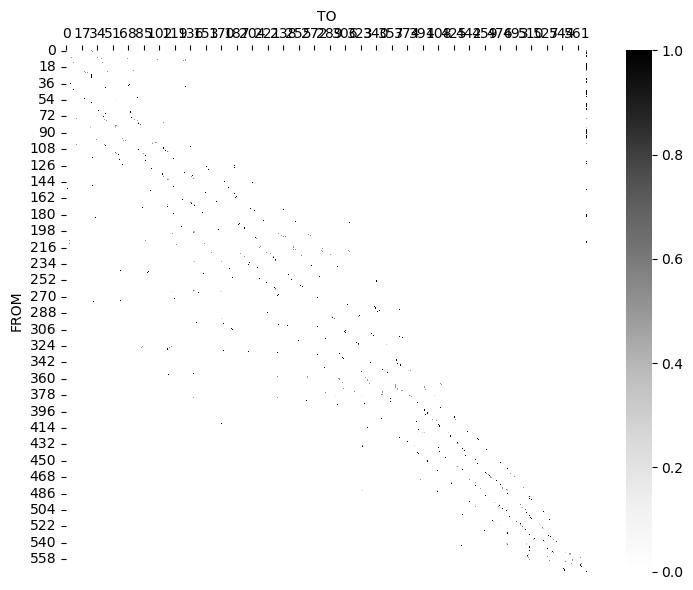

In [8]:
p.get_cm(res=res, study_area=study_area, t=-1, buffer=10)
p.plot_cm()

In [9]:
G = p.get_network()

((<Figure size 700x700 with 2 Axes>, <Axes: >),)

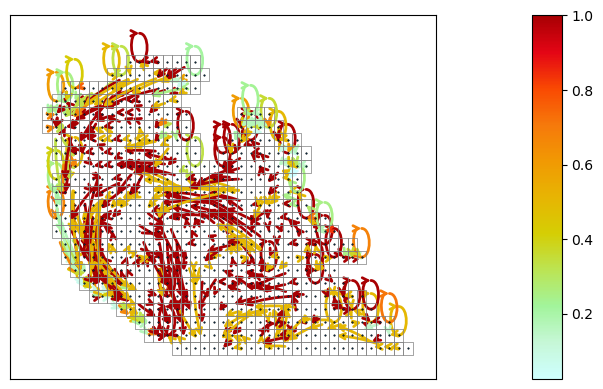

In [10]:
plotting._plot_network(
    G,
    node_shapes=p.cm_grid[:-1],
    show_map=False,
    node_size=1,
 #   rescale_edge=0.05
),  

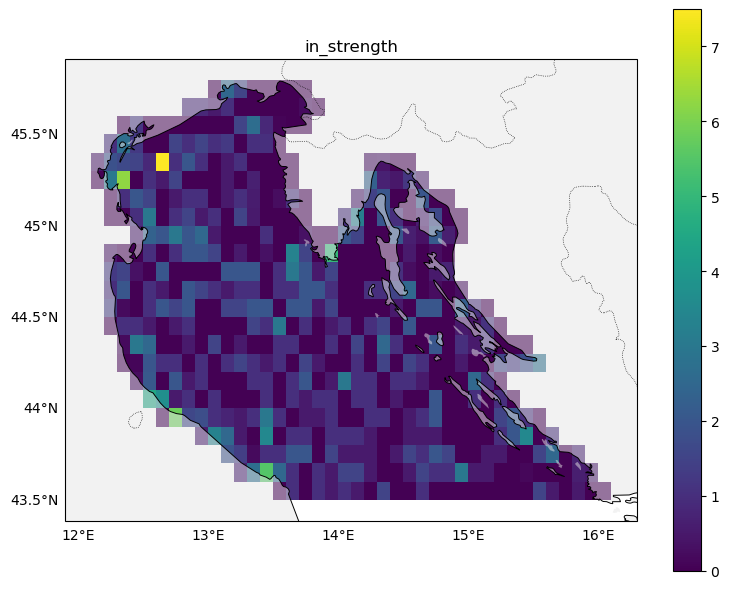

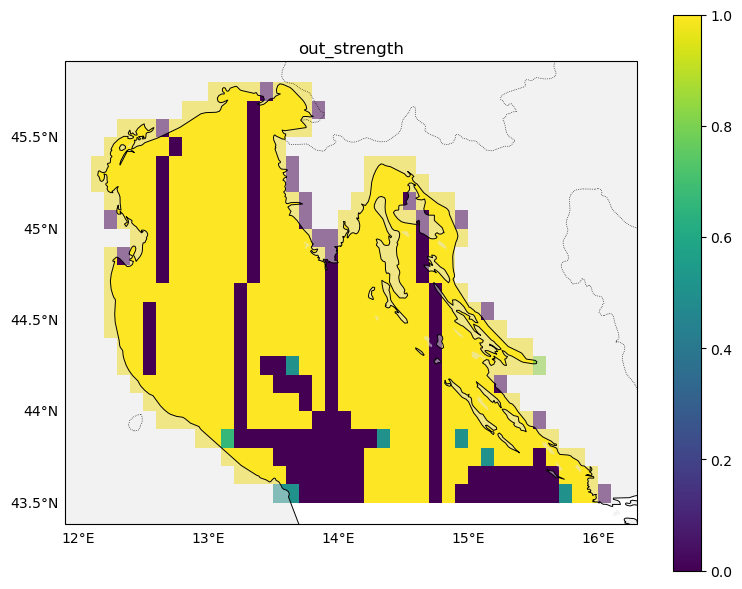

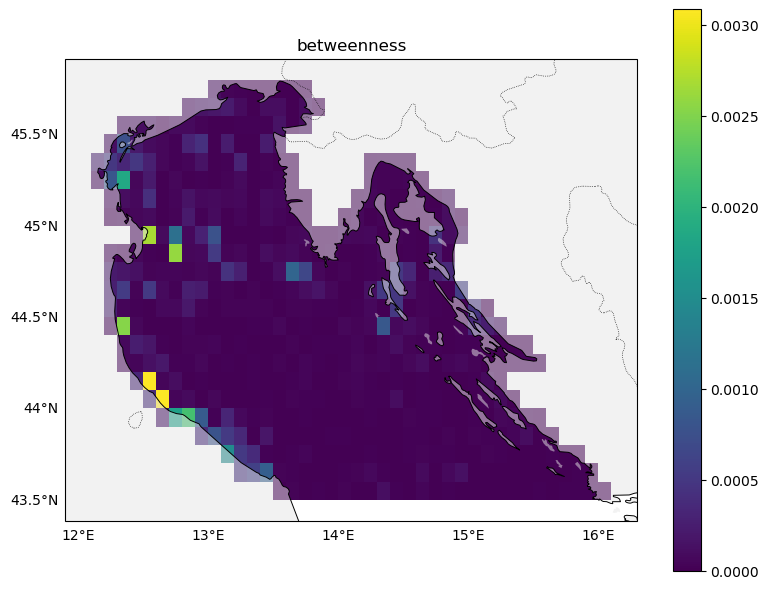

In [11]:
cdf = p.connectivity_analysis(plot=True)

## 3. Markov-chain prediction: `predict_with_cm`

Given a starting distribution (occupancy/probability per cell) and the transition matrix
`cm`, `predict_with_cm` propagates it forward `k` Markov steps: `v -> v @ cm^k`. Each step
corresponds to the same `t` used when the matrix was built (here, the full 2-day
transition from the basic run).

We reuse the `SUM` raster from section 1 as the starting distribution. `predict_with_cm`
reprojects its input onto whichever grid is currently set on `p.grid` — since we've used
the same `res`/`study_area` throughout, that's the same grid `SUM` was already computed
on, so this reprojection is effectively a no-op (important: feeding in a raster from a
*different* resolution than the connectivity matrix would silently distort results, since
reprojecting an additive quantity like a particle count onto a coarser grid via
nearest-neighbour resampling does not sum the finer cells it replaces).

2026-10-07 13:56:09,767 WARNING pmar:1736: initial_condition and cm dimensions do not match


(571,)
(571,)
148013.27393458676
Starting mass: 233706.0
Predicted mass: 148013.27393458676 (may be <= starting mass: some probability can leak outside the tracked domain)


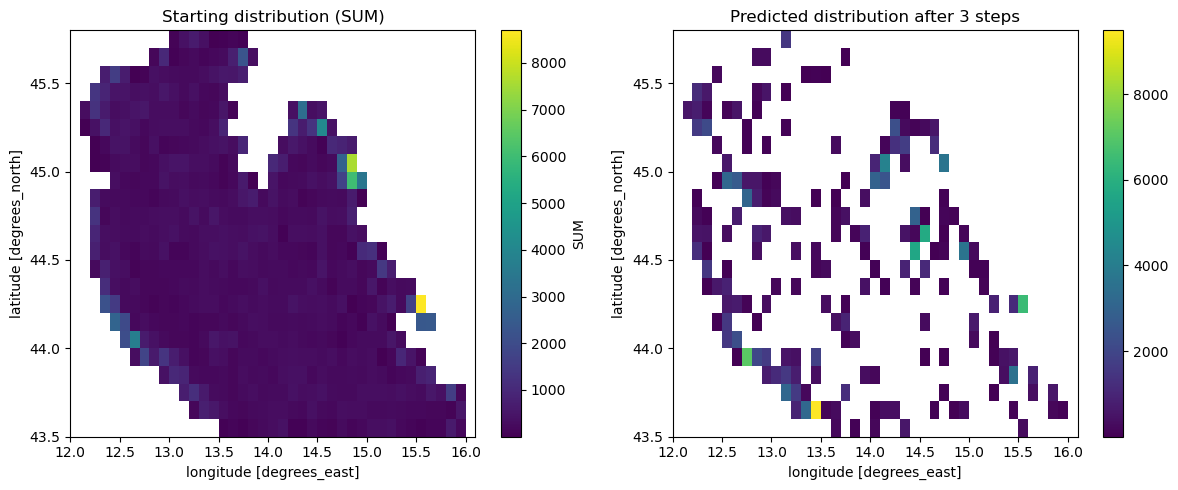

In [16]:
pred = p.predict_with_cm(p.output['SUM'], k=3)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
p.output['SUM'].where(p.output['SUM'] > 0).plot(ax=axs[0])
axs[0].set_title('Starting distribution (SUM)')
pred.where(pred > 0).plot(ax=axs[1])
axs[1].set_title('Predicted distribution after 3 steps')
plt.tight_layout()

print('Starting mass:', float(p.output['SUM'].sum()))
print('Predicted mass:', float(pred.sum()), '(may be <= starting mass: some probability can leak outside the tracked domain)')

## 4. Multi-seeding runs: `PMARmulti`

Everything so far used a single release of particles at one point in time. `PMARmulti`
repeats the same trajectory simulation across several seedings (offset by `tshift` days,
via `seedings`) and aggregates the results — useful for building indicators/connectivity
matrices that reflect typical conditions rather than being tied to one specific release
date.

Its API mirrors `PMAR`'s: `get_trajectories` takes the same parameters plus `seedings`/
`tshift`, and builds `self.ds` with an extra `seeding` dimension (one simulation per
seeding, concatenated together). `get_cm()` runs the single-seeding connectivity-matrix
calculation independently for each seeding and returns the average across all of them.

In [5]:
from pmar.pmar import PMARmulti

pm = PMARmulti(basedir='pmar_demo_output', loglevel=20)
pm.study_area = study_area

pm.run(
    pnum=100,
    start_time='2021-06-01',
    duration=1,
    seedings=3,
    tshift=1,
    res=res,
    study_area=study_area,
    seed_within_bounds=study_area,
    use='emodnet__routedensity_allavg',
    use_label='emodnet__routedensity_allavg'
)

2026-10-12 11:13:25,570 INFO    pmar:240: initializing pressure generic with opendrift module <class 'opendrift.models.oceandrift.OceanDrift'>
2026-10-12 11:13:25,578 INFO    pmar:200: auto-selected spatial_domain(s): ['med']
2026-10-12 11:13:25,579 INFO    pmar:445: auto-selected spatial_domain: auto: med
2026-10-12 11:13:25,581 INFO    pmar:2230: Starting rep #0 with start_time = 2021-06-01, end_time: None, and duration: 1
2026-10-12 11:13:25,591 INFO    pmar:527: created seeding_shapefile with bounds [12, 43.5, 16, 45.8]
2026-10-12 11:13:25,592 INFO    pmar:539: particle_path exists = True, pmar_demo_output/cachedir/38128f857ab4f2d485bf13b3c81f8920.nc
2026-10-12 11:13:25,594 INFO    pmar:546: Opendrift file with these configurations already exists within pmar_demo_output. Importing.
2026-10-12 11:13:25,610 INFO    pmar:716: particle simulation lat = (100, 25), lon=(100, 25), time=(25,)
2026-10-12 11:13:25,611 INFO    pmar:717: done. NetCDF file 'pmar_demo_output/cachedir/38128f857ab

string


2026-10-12 11:13:25,839 INFO    pmar:539: particle_path exists = True, pmar_demo_output/cachedir/61a080061a78adc61d31667f84e266d6.nc
2026-10-12 11:13:25,840 INFO    pmar:546: Opendrift file with these configurations already exists within pmar_demo_output. Importing.
2026-10-12 11:13:25,863 INFO    pmar:716: particle simulation lat = (100, 25), lon=(100, 25), time=(25,)
2026-10-12 11:13:25,864 INFO    pmar:717: done. NetCDF file 'pmar_demo_output/cachedir/61a080061a78adc61d31667f84e266d6.nc' created successfully.
2026-10-12 11:13:25,865 INFO    pmar:2235: Done with rep #1.
2026-10-12 11:13:25,866 INFO    pmar:2230: Starting rep #2 with start_time = 2021-06-03, end_time: None, and duration: 1
2026-10-12 11:13:25,930 INFO    pmar:527: created seeding_shapefile with bounds [12, 43.5, 16, 45.8]
2026-10-12 11:13:25,932 INFO    pmar:539: particle_path exists = True, pmar_demo_output/cachedir/2d60dd9278fdff1710cb214eee313dc4.nc
2026-10-12 11:13:25,933 INFO    pmar:546: Opendrift file with thes

string
ERROR! Session/line number was not unique in database. History logging moved to new session 7058
string
list


2026-10-12 11:13:30,797 INFO    pmar:240: initializing pressure generic with opendrift module <class 'opendrift.models.oceandrift.OceanDrift'>
2026-10-12 11:13:30,816 INFO    pmar:1193: ppi_exists = False, pmar_demo_output/ppi-emodnet__routedensity_allavg/4e28f5801da72f5d0b8d582d0d55eb26.tif


...

string


2026-10-12 11:13:47,081 WARNING pmar:959: (100, 25)
2026-10-12 11:13:47,111 INFO    pmar:882: sampling use value at particles' starting locations..
2026-10-12 11:13:47,118 INFO    pmar:888: number of trajectories with non-zero use value  97/100
2026-10-12 11:13:47,121 WARNING pmar:978: (100, 25)
2026-10-12 11:13:47,127 INFO    pmar:1046: calculated bin number at timestep 0.
2026-10-12 11:13:47,129 INFO    pmar:927: counts_per_bin...
2026-10-12 11:13:47,132 INFO    pmar:989: weight normalized by number of particles in bin at t0.
2026-10-12 11:13:47,133 WARNING pmar:990: (100, 25)
2026-10-12 11:13:47,136 INFO    pmar:1005: updating weight variable in ds
2026-10-12 11:13:51,062 INFO    pmar:2074: Wrote tiff to pmar_demo_output/ppi-emodnet__routedensity_allavg/6536718b18d3551c7abe912b18c8e766.tif.
2026-10-12 11:13:51,074 INFO    pmar:240: initializing pressure generic with opendrift module <class 'opendrift.models.oceandrift.OceanDrift'>
2026-10-12 11:13:51,103 INFO    pmar:1193: ppi_exist

string


2026-10-12 11:13:55,431 WARNING pmar:959: (100, 25)
2026-10-12 11:13:55,464 INFO    pmar:882: sampling use value at particles' starting locations..
2026-10-12 11:13:55,471 INFO    pmar:888: number of trajectories with non-zero use value  97/100
2026-10-12 11:13:55,474 WARNING pmar:978: (100, 25)
2026-10-12 11:13:55,478 INFO    pmar:1046: calculated bin number at timestep 0.
2026-10-12 11:13:55,480 INFO    pmar:927: counts_per_bin...
2026-10-12 11:13:55,483 INFO    pmar:989: weight normalized by number of particles in bin at t0.
2026-10-12 11:13:55,484 WARNING pmar:990: (100, 25)
2026-10-12 11:13:55,485 INFO    pmar:1005: updating weight variable in ds
2026-10-12 11:13:59,515 INFO    pmar:2074: Wrote tiff to pmar_demo_output/ppi-emodnet__routedensity_allavg/00338243cb257d64d7705c105283eed5.tif.
2026-10-12 11:13:59,787 INFO    pmar:2074: Wrote tiff to pmar_demo_output/ppi-emodnet__routedensity_allavg/924f77dfb6b2e1a7af91820749d4c05c.tif.


list


In [8]:
pm.get_indicators(res=res, study_area=study_area)#, dim=['trajectory','time'], weighted=False)

In [9]:
pm.get_ppi(res=res, study_area=study_area)

2026-10-12 11:16:11,303 INFO    pmar:2285: PPI with requested configurations found in cache.


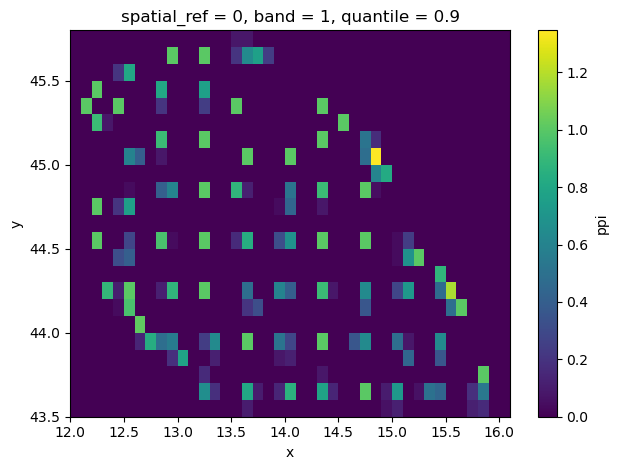

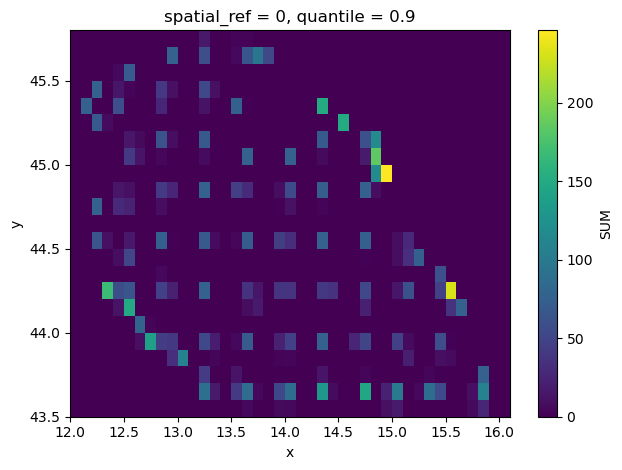

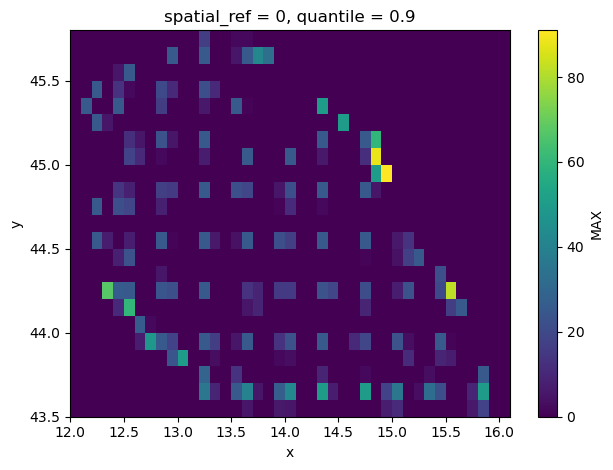

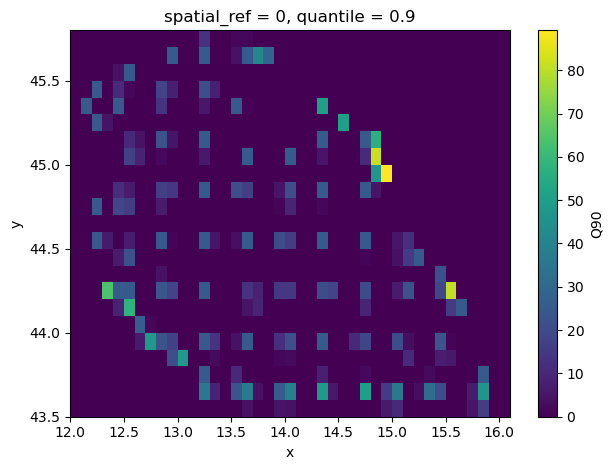

In [14]:
for var in pm.output.data_vars:
    plt.figure()
    pm.output[var].plot()

2026-10-12 12:29:08,363 INFO    pmar:2508: Calculating average cm out of 3 particle files.
2026-10-12 12:29:08,395 INFO    pmar:240: initializing pressure generic with opendrift module <class 'opendrift.models.oceandrift.OceanDrift'>


ds


2026-10-12 12:29:12,418 WARNING pmar:959: (100, 24)
2026-10-12 12:29:12,469 INFO    pmar:882: sampling use value at particles' starting locations..
2026-10-12 12:29:12,476 INFO    pmar:888: number of trajectories with non-zero use value  97/100
2026-10-12 12:29:12,478 WARNING pmar:978: (100, 24)
2026-10-12 12:29:12,480 INFO    pmar:1005: updating weight variable in ds
2026-10-12 12:29:20,691 INFO    pmar:2530: Done calculating cm for particle file 0.
2026-10-12 12:29:20,692 INFO    pmar:2508: Calculating average cm out of 3 particle files.
2026-10-12 12:29:20,707 INFO    pmar:240: initializing pressure generic with opendrift module <class 'opendrift.models.oceandrift.OceanDrift'>


ds


2026-10-12 12:29:24,664 WARNING pmar:959: (100, 24)
2026-10-12 12:29:24,700 INFO    pmar:882: sampling use value at particles' starting locations..
2026-10-12 12:29:24,708 INFO    pmar:888: number of trajectories with non-zero use value  97/100
2026-10-12 12:29:24,711 WARNING pmar:978: (100, 24)
2026-10-12 12:29:24,713 INFO    pmar:1005: updating weight variable in ds
2026-10-12 12:29:33,397 INFO    pmar:2530: Done calculating cm for particle file 1.
2026-10-12 12:29:33,399 INFO    pmar:2508: Calculating average cm out of 3 particle files.
2026-10-12 12:29:33,411 INFO    pmar:240: initializing pressure generic with opendrift module <class 'opendrift.models.oceandrift.OceanDrift'>


ds


2026-10-12 12:29:37,356 WARNING pmar:959: (100, 24)
2026-10-12 12:29:37,387 INFO    pmar:882: sampling use value at particles' starting locations..
2026-10-12 12:29:37,394 INFO    pmar:888: number of trajectories with non-zero use value  97/100
2026-10-12 12:29:37,397 WARNING pmar:978: (100, 24)
2026-10-12 12:29:37,398 INFO    pmar:1005: updating weight variable in ds
2026-10-12 12:29:45,740 INFO    pmar:2530: Done calculating cm for particle file 2.


list


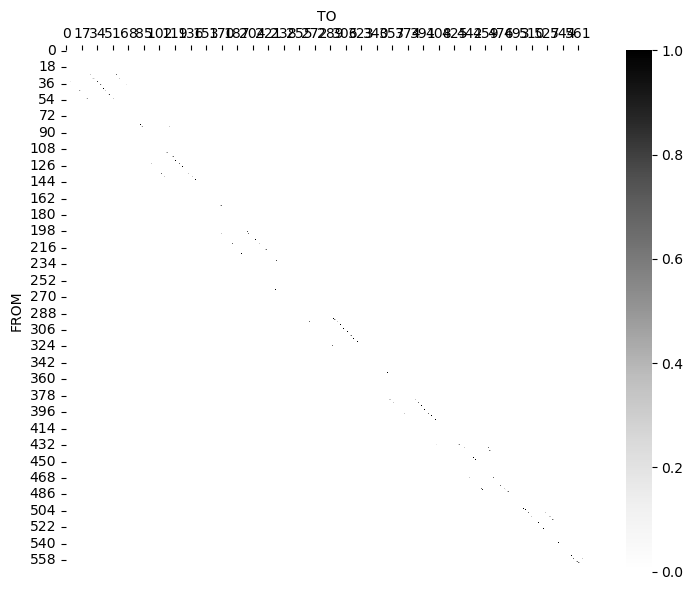

In [15]:
pm.get_cm(res=res, study_area=study_area, t0=0, t1=-1)
pm.plot_cm()

## Where to go next

This notebook covered the core single-seeding workflow. A few other things PMAR can do:

- **Other pressure types**: pass `pressure='plastic'|'chemical'|'oil'|'metal'|'larvae'`
  to `PMAR(...)` instead of the default `'generic'` to use OpenDrift's specialized
  modules (e.g. `chemical_compound=` for `'chemical'`/`'metal'`).
- **Dispersal distance**: `p.dispersal_distance()` computes the probability-weighted
  mean distance travelled from each cell, directly from the connectivity matrix.
- **`PMARmulti.run(...)`** bundles `get_trajectories` + `get_ppi` + `get_indicators` into
  a single call for the multi-seeding case too, for when you don't need the intermediate
  steps shown in section 4.